In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [ ]:
#Had to change - flux values to 0 in the data file (made a copy though) 
#Also deleted epochs 10a and 10b
#Non detections done correctly 
#Removed alpha values for those epochs too 
#All tick marks good 

In [3]:
#Eruption: 03-26-2014 

#The Radio data
V1534_radio = pd.read_csv('v1534_Radio.txt', delim_whitespace = True, header = 0)

freq = V1534_radio['Freq(GHz)']
flux = V1534_radio['Flux(mJy)']
err = V1534_radio['eFlux(mJy)']
mjd = V1534_radio['MJD']

mjd

/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_20196/2359081813.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  V1534_radio = pd.read_csv('v1534_Radio.txt', delim_whitespace = True, header = 0)


0      56747.5
1      56747.5
2      56757.5
3      56757.5
4      56757.5
        ...   
108    57360.7
109    57360.7
110    57360.7
111    57360.7
112    57360.7
Name: MJD, Length: 113, dtype: float64

In [4]:
#mjd to date 
#mjd t_0 = 56742

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(mjd,56742))

In [14]:
56952.9 -  56742

210.90000000000146

In [5]:
day

array([  5.5,   5.5,  15.5,  15.5,  15.5,  15.5,  17.5,  17.5,  17.5,
        17.5,  26.4,  26.4,  26.4,  26.4,  26.4,  26.4,  26.4,  26.4,
        32.4,  32.4,  32.4,  32.4,  34.4,  34.4,  34.4,  34.4,   nan,
        46.3,  46.3,  46.3,  46.3,   nan,  48.4,  48.4,  48.4,  48.4,
         nan,  79.3,  79.3,  79.3,  79.3,  85.2,  85.2,  85.2,  85.2,
        99.2,  99.2,  99.2,  99.2, 109.2, 109.2, 109.2, 109.2, 139. ,
       139. , 139. , 139. , 166.1, 166.1, 166.1, 166.1, 194.6, 194.6,
       194.6, 194.6, 227.8, 227.8, 227.8, 227.8, 227.9, 227.9, 227.9,
       227.9, 255.8, 255.8, 255.8, 255.8, 261.7, 261.7, 261.7, 261.7,
       297.6, 297.6, 297.6, 297.6, 297.7, 297.7, 297.7, 297.7, 340.6,
       340.6, 340.6, 340.6, 343.5, 343.5, 343.5, 343.5, 394.4, 394.4,
       394.4, 394.4, 398.4, 398.4, 398.4, 398.4, 618.7, 618.7, 618.7,
       618.7, 618.7, 618.7, 618.7, 618.7])

In [10]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 0, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 5)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


###############################################################
D = np.logical_and(freq>= 6, freq<= 8) 
C_BD = np.where(np.logical_and(D, flux > 3*err)) 
C_nbd = np.where(np.logical_and(D, flux < 3*err))

freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([err[i] for i in C_BD])
date_CBD = np.ravel([day[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] + err[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([day[i] for i in C_nbd])

###############################################################
E = np.logical_and(freq>= 10, freq<= 14)
Ku_AC =  np.where(np.logical_and(E, flux > 3*err))  
Ku_nac = np.where(np.logical_and(E, flux < 3*err))  

freq_K_AC = np.ravel([freq[i] for i in Ku_AC])
flux_K_AC = np.ravel([flux[i] for i in Ku_AC])
err_K_AC  = np.ravel([err[i] for i in Ku_AC])
date_K_AC = np.ravel([day[i] for i in Ku_AC])

nflux_K_AC = np.ravel([flux[i] + err[i]*3 for i in Ku_nac])
ndate_K_AC = np.ravel([day[i] for i in Ku_nac])
###############################################################
F = np.logical_and(freq>= 15, freq<= 20)
Ku_BD =  np.where(np.logical_and(F, flux > 3*err))  
Ku_nbd = np.where(np.logical_and(F, flux < 3*err))  

freq_K_BD = np.ravel([freq[i] for i in Ku_BD])
flux_K_BD = np.ravel([flux[i] for i in Ku_BD])
err_K_BD  = np.ravel([err[i] for i in Ku_BD])
date_K_BD = np.ravel([day[i] for i in Ku_BD])

nflux_K_BD = np.ravel([flux[i] + err[i]*3 for i in Ku_nbd])
ndate_K_BD = np.ravel([day[i] for i in Ku_nbd])
###############################################################

G = np.logical_and(freq>= 21, freq<= 30)
Ka_AC =  np.where(np.logical_and(G, flux > 3*err)) 
Ka_nac = np.where(np.logical_and(G, flux < 3*err)) 

freq_Ka_AC = np.ravel([freq[i] for i in Ka_AC])
flux_Ka_AC = np.ravel([flux[i] for i in Ka_AC])
err_Ka_AC  = np.ravel([err[i] for i in Ka_AC])
date_Ka_AC = np.ravel([day[i] for i in Ka_AC])

nflux_Ka_AC = np.ravel([flux[i] + err[i]*3 for i in Ka_nac])
ndate_Ka_AC = np.ravel([day[i] for i in Ka_nac])
###############################################################

H = np.logical_and(freq>= 31, freq<= 40)
Ka_BD =  np.where(np.logical_and(H, flux > 3*err))  
Ka_nbd = np.where(np.logical_and(H, flux < 3*err))

freq_Ka_BD = np.ravel([freq[i] for i in Ka_BD])
flux_Ka_BD = np.ravel([flux[i] for i in Ka_BD])
err_Ka_BD  = np.ravel([err[i] for i in Ka_BD])
date_Ka_BD = np.ravel([day[i] for i in Ka_BD])

nflux_Ka_BD = np.ravel([flux[i] + err[i]*3 for i in Ka_nbd])
ndate_Ka_BD = np.ravel([day[i] for i in Ka_nbd])

In [11]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [12]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD)
quad_Kac = quad(err_K_AC,freq_K_AC, flux_K_AC)
quad_Kbd = quad(err_K_BD,freq_K_BD, flux_K_BD)
quad_Kaac = quad(err_Ka_AC,freq_Ka_AC, flux_Ka_AC)
quad_Kabd = quad(err_Ka_BD,freq_Ka_BD, flux_Ka_BD)


# Now for the optical data 

In [13]:
#optical data input

V1534Sco_opt_unfiltered = pd.read_csv('V1534Sco_Optical.txt',sep='\s+', header=0)
#V1534Sco_opt_unfiltered = pd.read_csv('V1534Sco_Opti.txt', header = 0)

#now to get only the vband

column_name = 'band'
key = 'V'

V1534_opt_kinda = V1534Sco_opt_unfiltered[V1534Sco_opt_unfiltered[column_name].str.contains(key, na=False)]

V1534_opt = V1534_opt_kinda[~V1534_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]

V1534_opt

,JD(+2450000.0),band,Mag.,+/-,Flux(F_lam),seeingarcsec,yymmdd,source
5,6747.80811,V,12.609,0.003,3.270000e-14,140330.00,Andicam,NaN
9,6748.79590,V,12.969,0.003,2.340000e-14,140331.00,Andicam,NaN
13,6749.81006,V,13.381,0.002,1.600000e-14,140401.00,Andicam,NaN
17,6750.72803,V,13.688,0.002,1.210000e-14,140402.00,Andicam,NaN
21,6751.74902,V,14.003,0.004,9.050000e-15,140403.00,Andicam,NaN
...,...,...,...,...,...,...,...,...
413,8016.57178,V,17.582,0.003,3.350000e-16,1.01,170919,Andicam
417,8046.50879,V,17.938,0.003,2.410000e-16,0.79,171019,Andicam
421,8188.87500,V,17.649,0.002,3.150000e-16,0.64,180310,Andicam
425,8208.79688,V,18.205,0.003,1.890000e-16,0.60,180330,Andicam


In [14]:
#MJD = JD - 2400000.5 
# 56742

JD_first = 56742 + 2400000.5 
print(JD_first)

opticaldays = (((V1534_opt['JD(+2450000.0)'].astype(float) + 2450000.0)) - 2456742.5)
vmag = V1534_opt['Mag.'].astype(float)
error_vmag = V1534_opt['+/-'].astype(float)

2456742.5


In [15]:
np.min(vmag)

12.609

# Now both together

In [18]:
#spectral index

SI = [ -1.32, -0.21, -1.59, -0.62, -0.56, -0.67, -0.94, -1.49, -0.62, -0.63, -0.89, -0.91, -0.35, -0.55, -1.30, 0.33, -0.10, -0.27, 0.22]
SI_E =[0.83, 0.14,  0.29,  0.06,  0.04,  0.09,  0.37,  0.18,  0.02, 0.12,   0.05,  0.11,  0.23,  0.08,  0.43, 0.99, 0.34, 0.22, 0.55]
SI_D =[4.7, 14.7,  16.7,  25.6,  32.6,  46.5,  78.5,  84.4,  98.4, 108.4,  138.2,  165.3,  193.8, 227.0, 255.0, 260.9, 296.8, 341.25, 393.6] 


s1 = -0.60 
s1_e = 0.22

s2 = 0.40
s2_e = 0.87 

sday = 209.1

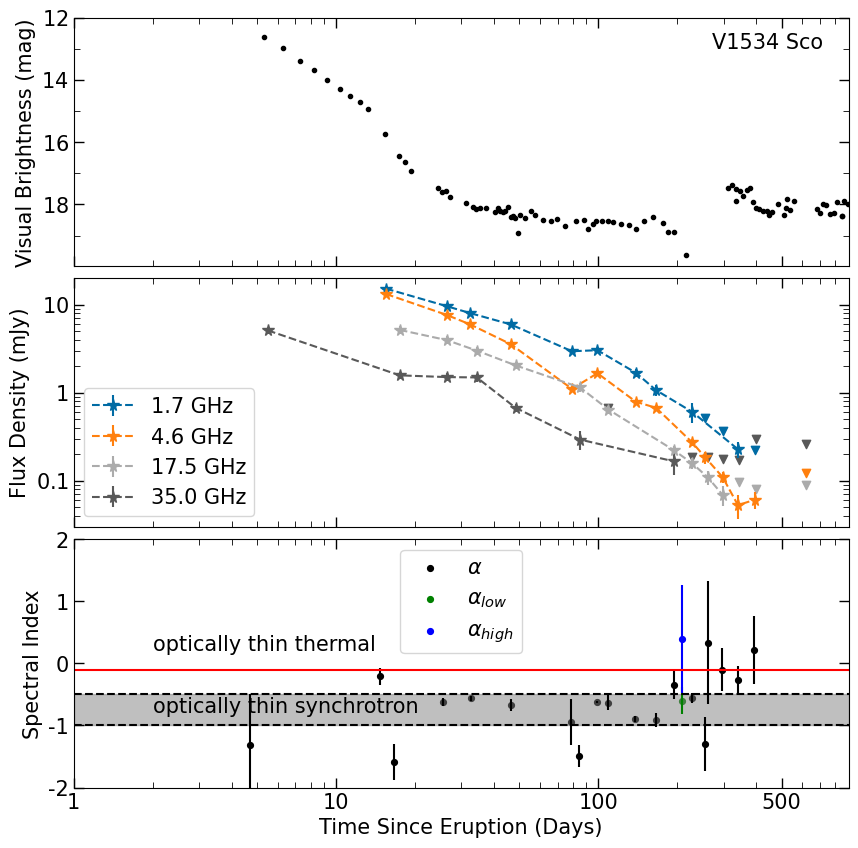

In [22]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V1534 Sco',(270,13), fontsize=15)

axs[0].set_xscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

axs[0].set_yticks([12,14,16,18], labels = [r'$12$', r'$14$',r'$16$', r'$18$'], fontsize = 15)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2)) 
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].set_xlim([4,900])
axs[1].set_ylim([0.03,20])



axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.7 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.6 GHz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='17.5 GHz')
axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='35.0 GHz')


axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
axs[1].scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')


axs[1].legend(fontsize=15, loc='lower left')

axs[1].set_yticks([0.1,1.0,10], labels = [r'$0.1$',r'$1$',r'$10$'], fontsize = 15)

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

########## Panel 3 #############

axs[2].errorbar(SI_D,SI, yerr = SI_E, color = 'black', ls='None')
axs[2].scatter(SI_D, SI, color = 'black', marker = '.', s=70, label=r'$\alpha$')

axs[2].errorbar(sday,s1, yerr = s1_e, color = 'green', ls='None')
axs[2].scatter(sday, s1, color = 'green', marker = '.', s=70, label=r'$\alpha_{low}$')

axs[2].errorbar(sday,s2, yerr = s2_e, color = 'blue', ls='None')
axs[2].scatter(sday, s2, color = 'blue', marker = '.', s=70, label=r'$\alpha_{high}$')

axs[2].legend(fontsize=15)

axs[2].set_xscale('log')

axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[1,900],y1=-0.5,y2=-1, color = 'grey', alpha=.5)


axs[2].annotate('optically thin synchrotron', (2,-0.8), fontsize=15)
axs[2].annotate('optically thin thermal', (2,0.2), fontsize=15)

axs[2].set_xticks([1,10,100,500], labels = ['1','10','100','500'], fontsize = 15)
axs[2].set_yticks([-2,-1,0,1.0,2], labels = ['-2','-1','0','1','2'], fontsize = 15)
axs[2].set_ylim(-2,2)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize = 15)



fig.subplots_adjust(hspace=0.05)
plt.savefig("V1534Sco_3tier_lightcurves.png")
plt.show();